# Stock Market Data Analytics: NSE Portfolio Exploration

**Project Goal:** Build an automated pipeline to fetch, clean, analyze, and visualize historical intraday data (5-minute intervals) for major Indian stocks (Reliance, TCS, Infosys). 

**Author:** Anandhu Suresh
**Data Frequency:** 5-Minute Intraday (Last 60 Days)

In [1]:
# Import standard libraries
import sys
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore warnings for cleaner output
warnings.filterwarnings('ignore')

# Add the project root to sys.path so the notebook can find the 'src' folder
sys.path.append('..')

# Import your custom modules
from src.data_fetcher import fetch_market_data
from src.data_cleaner import clean_pipeline, describe_quality
import src.analysis as ana
import src.visualization as vis

## 1. Data Acquisition
We fetch the most recent 60 days of 5-minute interval data for our three target tickers. We use `force_refresh=True` to ensure we get the absolute latest market snapshot.

In [2]:
tickers = ["RELIANCE.NS", "TCS.NS", "INFY.NS"]

# Fetch raw data (forces a new download from Yahoo Finance)
raw_df = fetch_market_data(tickers, interval="5m", force_refresh=True)

print(f"\nData downloaded successfully. Shape: {raw_df.shape}")
print("Sample of raw data:")
display(raw_df.tail(3))

Saved 13167 rows to multi_ticker_5m.csv

Data downloaded successfully. Shape: (13167, 6)
Sample of raw data:


,Open,High,Low,Close,Volume,Ticker
Date,,,,,,
2026-11-13 15:25:00+05:30,2407.500000,2407.500000,2407.500000,2407.500000,87081,TCS.NS
2026-11-13 15:25:00+05:30,1339.699951,1339.699951,1339.699951,1339.699951,512357,RELIANCE.NS
2026-11-13 15:25:00+05:30,1141.500000,1141.500000,1141.500000,1141.500000,392643,INFY.NS


## 2. Feature Engineering
The raw data only gives us OHLCV. We use our `data_cleaner.py` pipeline to calculate technical indicators (Moving Averages, RSI, Bollinger Bands) securely grouped by each individual Ticker so the data doesn't mix.

In [3]:
# Run the cleaning pipeline
clean_df = clean_pipeline(raw_df)

# Print the data quality report
print("--- DATA QUALITY REPORT ---")
print(describe_quality(clean_df))

# Show the newly created features
print("\nSample of engineered features:")
display(clean_df[['Ticker', 'Close', 'SMA_20', 'RSI_14', 'BB_Upper']].tail(3))

--- DATA QUALITY REPORT ---
Total Rows                   13167
Unique Tickers                   3
Total Columns                   15
Missing Values                 480
Start Date        2026-08-18 09:15
End Date          2026-11-13 15:25
dtype: object

Sample of engineered features:


,Ticker,Close,SMA_20,RSI_14,BB_Upper
Date,,,,,
2026-11-13 15:25:00+05:30,TCS.NS,2407.500000,2406.575024,59.291988,2412.915465
2026-11-13 15:25:00+05:30,RELIANCE.NS,1339.699951,1337.354987,67.441662,1341.144429
2026-11-13 15:25:00+05:30,INFY.NS,1141.500000,1138.620001,75.862214,1140.845803


## 3. Statistical Analysis
We evaluate the risk and return profile of each stock. 
* **Sharpe Ratio** measures risk-adjusted return (higher is better). 
* **Kurtosis** measures the "fat tails" (extreme price swings).
* **Correlation** shows how stocks move together.

In [4]:
print("--- EXPECTED RETURNS (Avg 5-min) ---")
print(ana.calculate_expected_returns(clean_df))

print("\n--- SHARPE RATIO ---")
print(ana.calculate_sharpe_ratio(clean_df))

print("\n--- SKEW & KURTOSIS ---")
print(ana.get_return_distribution(clean_df))

print("\n--- CORRELATION MATRIX ---")
corr = ana.calculate_correlation(clean_df)
display(corr)

--- EXPECTED RETURNS (Avg 5-min) ---
Ticker
INFY.NS        0.000008
RELIANCE.NS    0.000006
TCS.NS         0.000015
Name: Simple_Return, dtype: float64

--- SHARPE RATIO ---
Ticker
INFY.NS        0.3967
RELIANCE.NS    0.4760
TCS.NS         0.7658
Name: Simple_Return, dtype: float64

--- SKEW & KURTOSIS ---
Ticker               
INFY.NS      Skewness      0.5245
             Kurtosis     99.2440
RELIANCE.NS  Skewness      5.0473
             Kurtosis    139.5431
TCS.NS       Skewness      4.1397
             Kurtosis     95.6266
Name: Simple_Return, dtype: float64

--- CORRELATION MATRIX ---


Ticker,INFY.NS,RELIANCE.NS,TCS.NS
Ticker,,,
INFY.NS,1.000000,0.149557,0.724555
RELIANCE.NS,0.149557,1.000000,0.190214
TCS.NS,0.724555,0.190214,1.000000


## 4. Visualizations
The `visualization.py` module saves high-resolution charts to the `visualizations/` folder. We can display them directly in the notebook using the `IPython.display` module.

Saved: E:\DataAnalytics\Projects\Stock_Market_Data_Exploring\visualizations\RELIANCE_NS_moving_averages.png
Saved: E:\DataAnalytics\Projects\Stock_Market_Data_Exploring\visualizations\TCS_NS_bollinger_bands.png
Saved: E:\DataAnalytics\Projects\Stock_Market_Data_Exploring\visualizations\INFY_NS_rsi.png
Saved: E:\DataAnalytics\Projects\Stock_Market_Data_Exploring\visualizations\correlation_heatmap.png
Saved: E:\DataAnalytics\Projects\Stock_Market_Data_Exploring\visualizations\return_distribution.png

--- RELIANCE.NS: MOVING AVERAGES ---


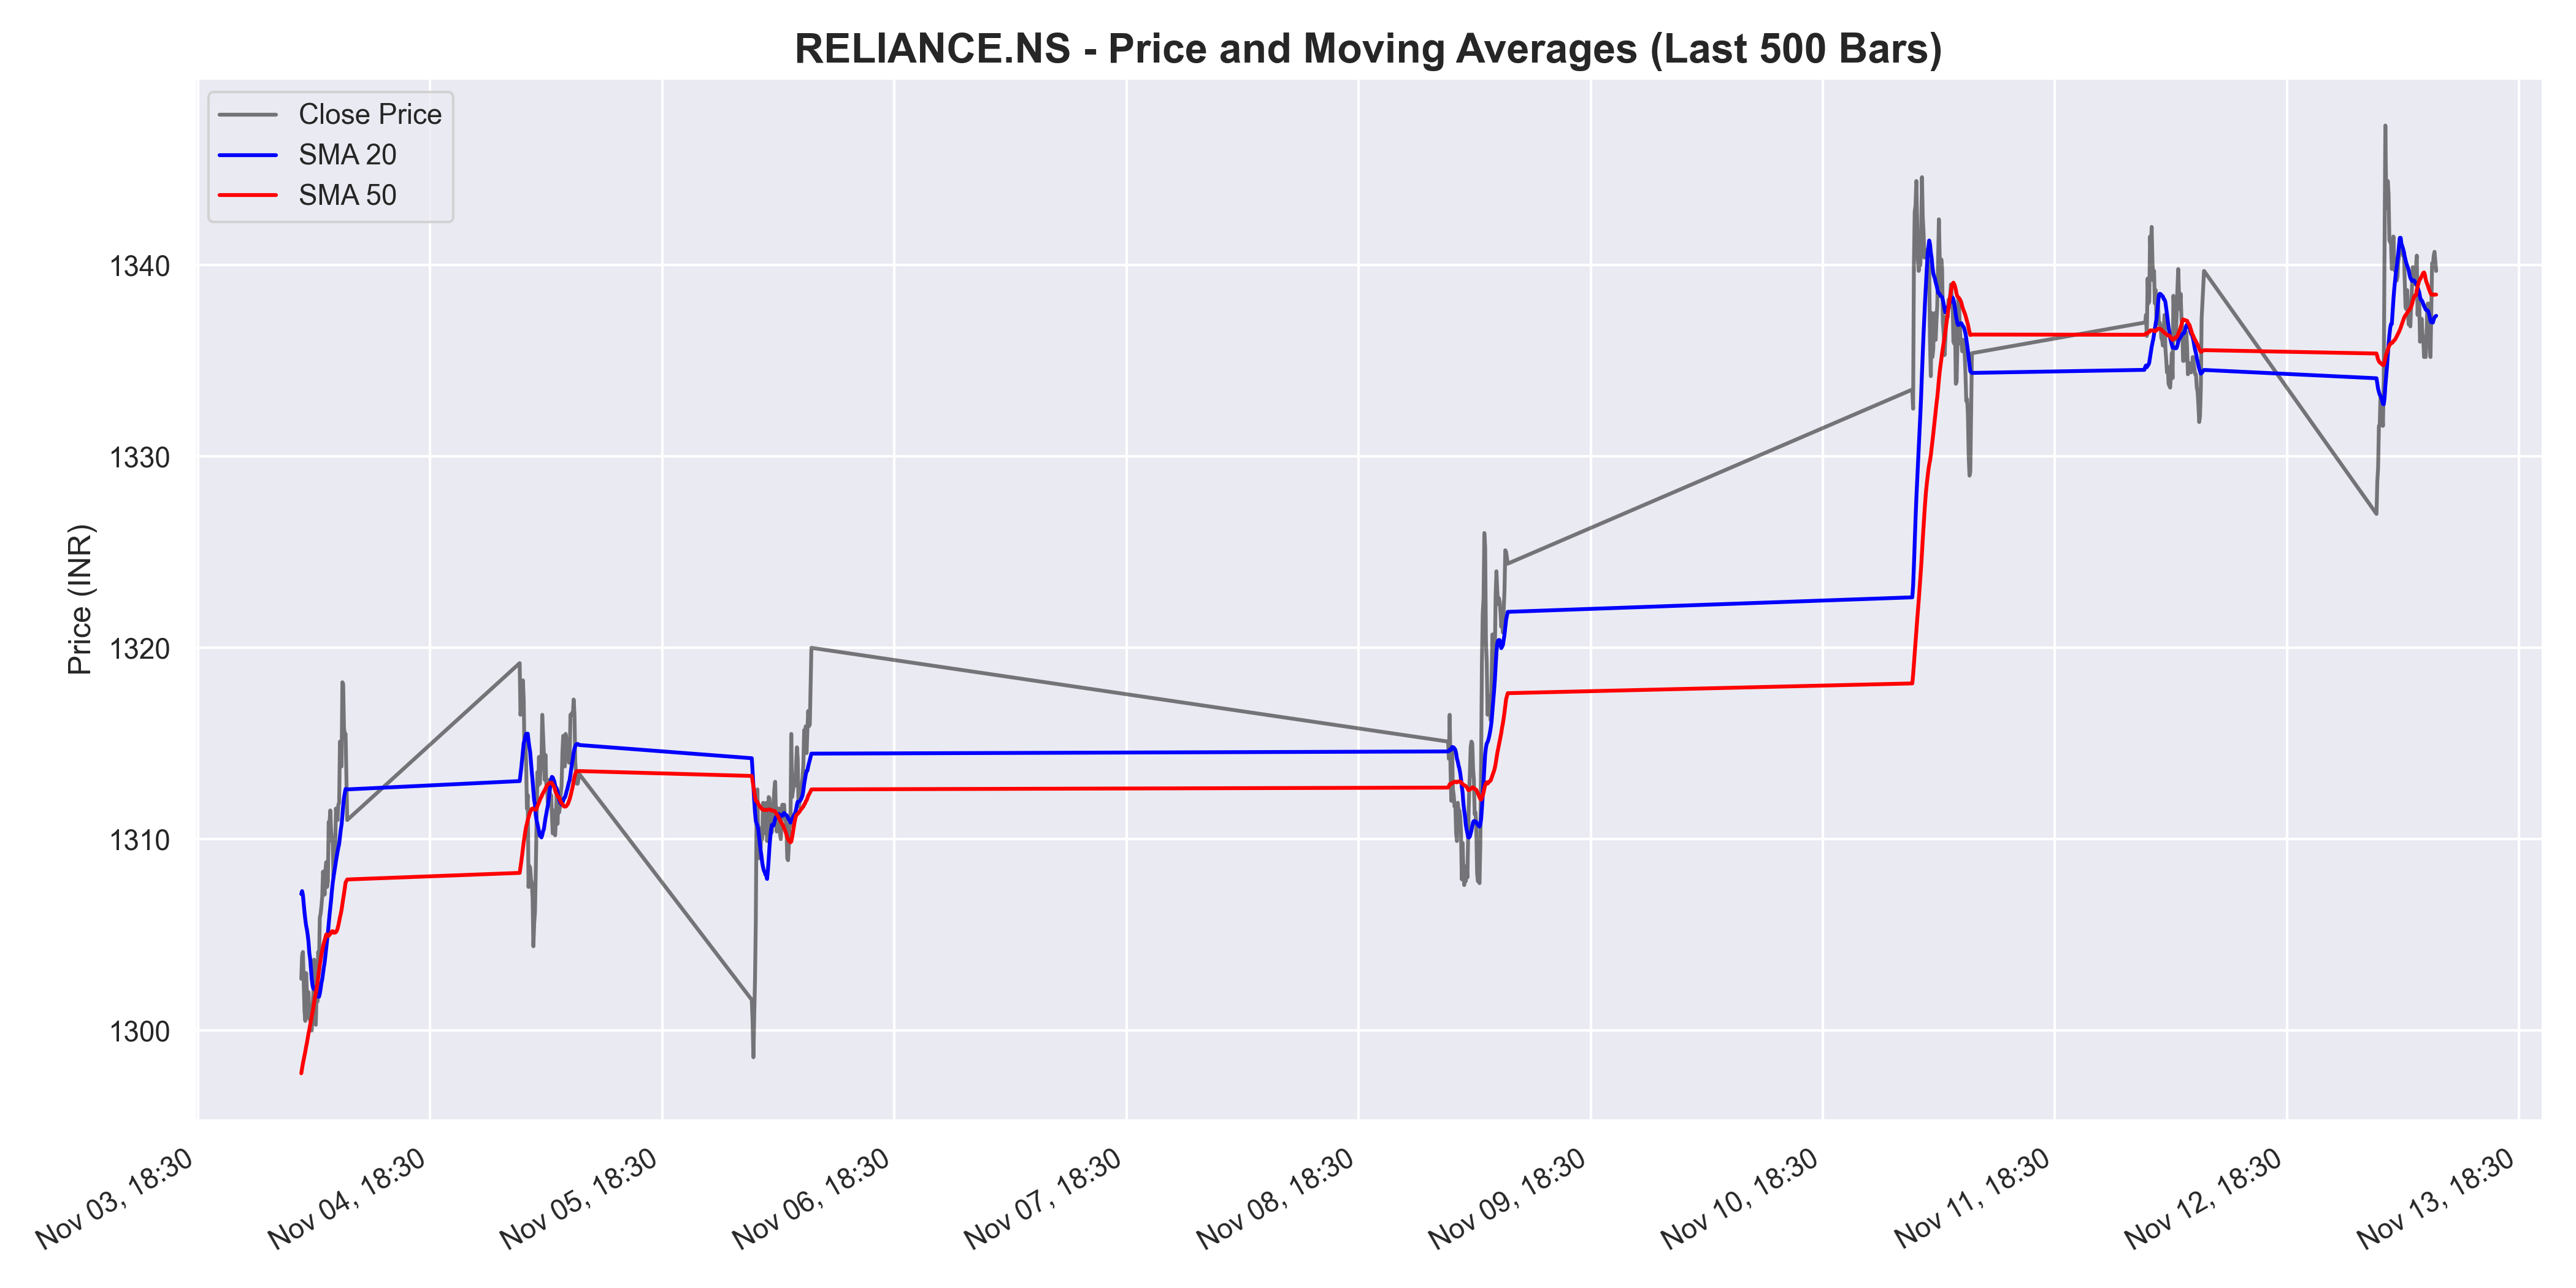


--- TCS.NS: BOLLINGER BANDS ---


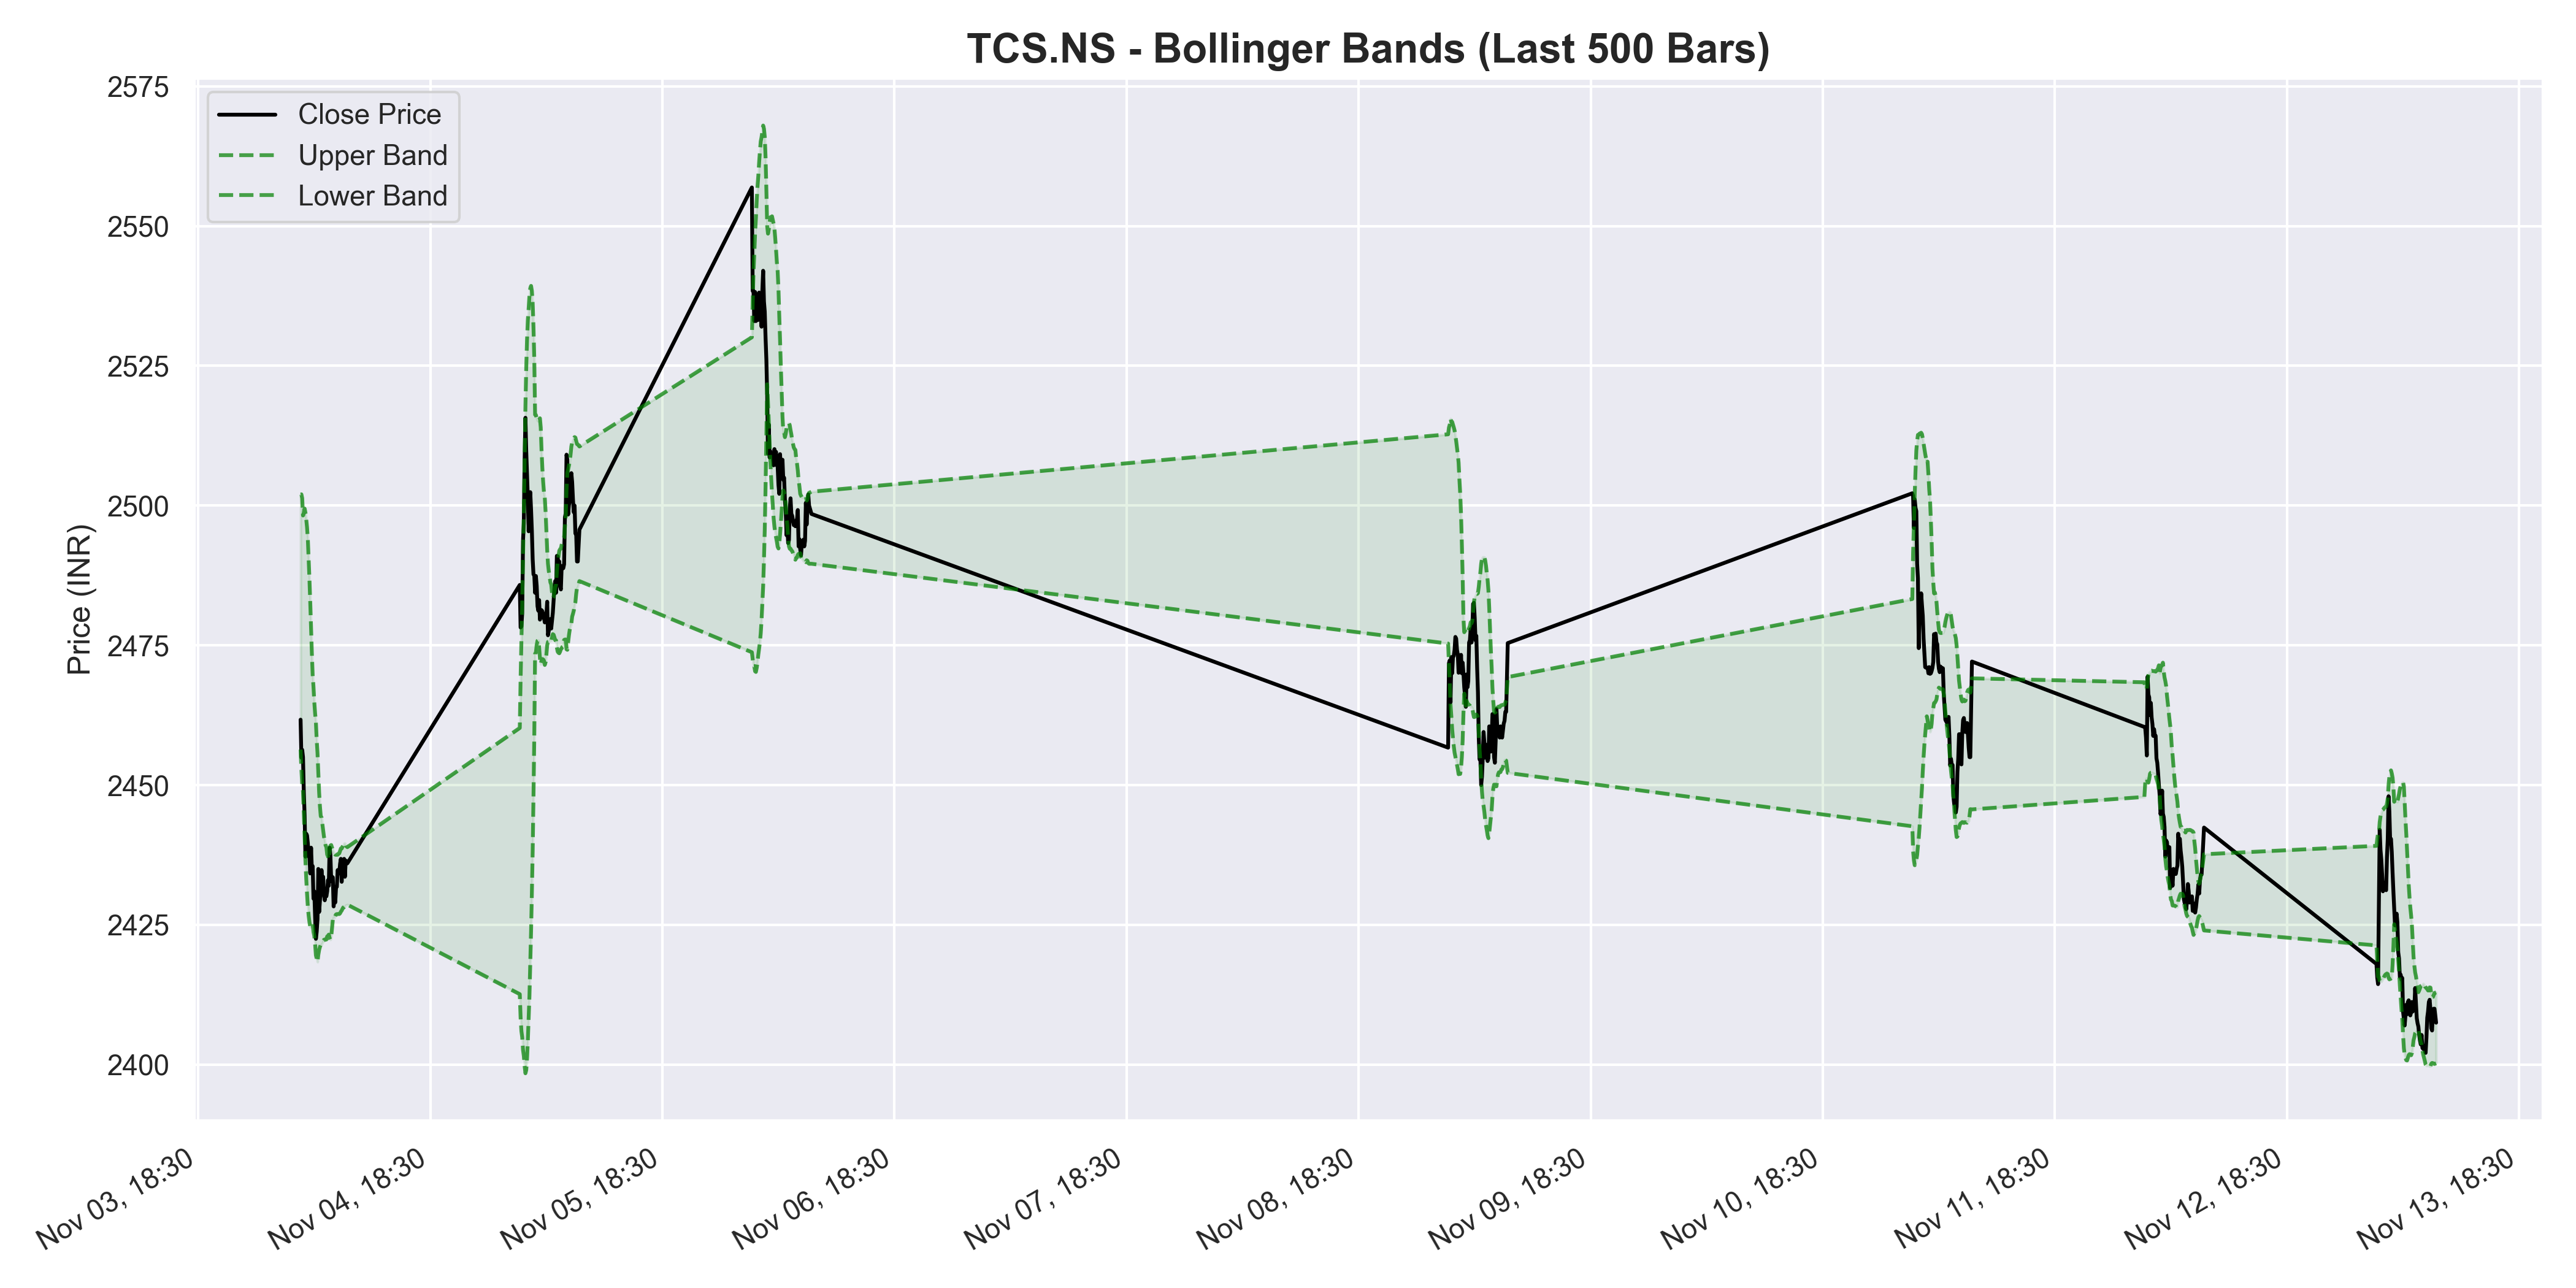


--- INFY.NS: RSI ---


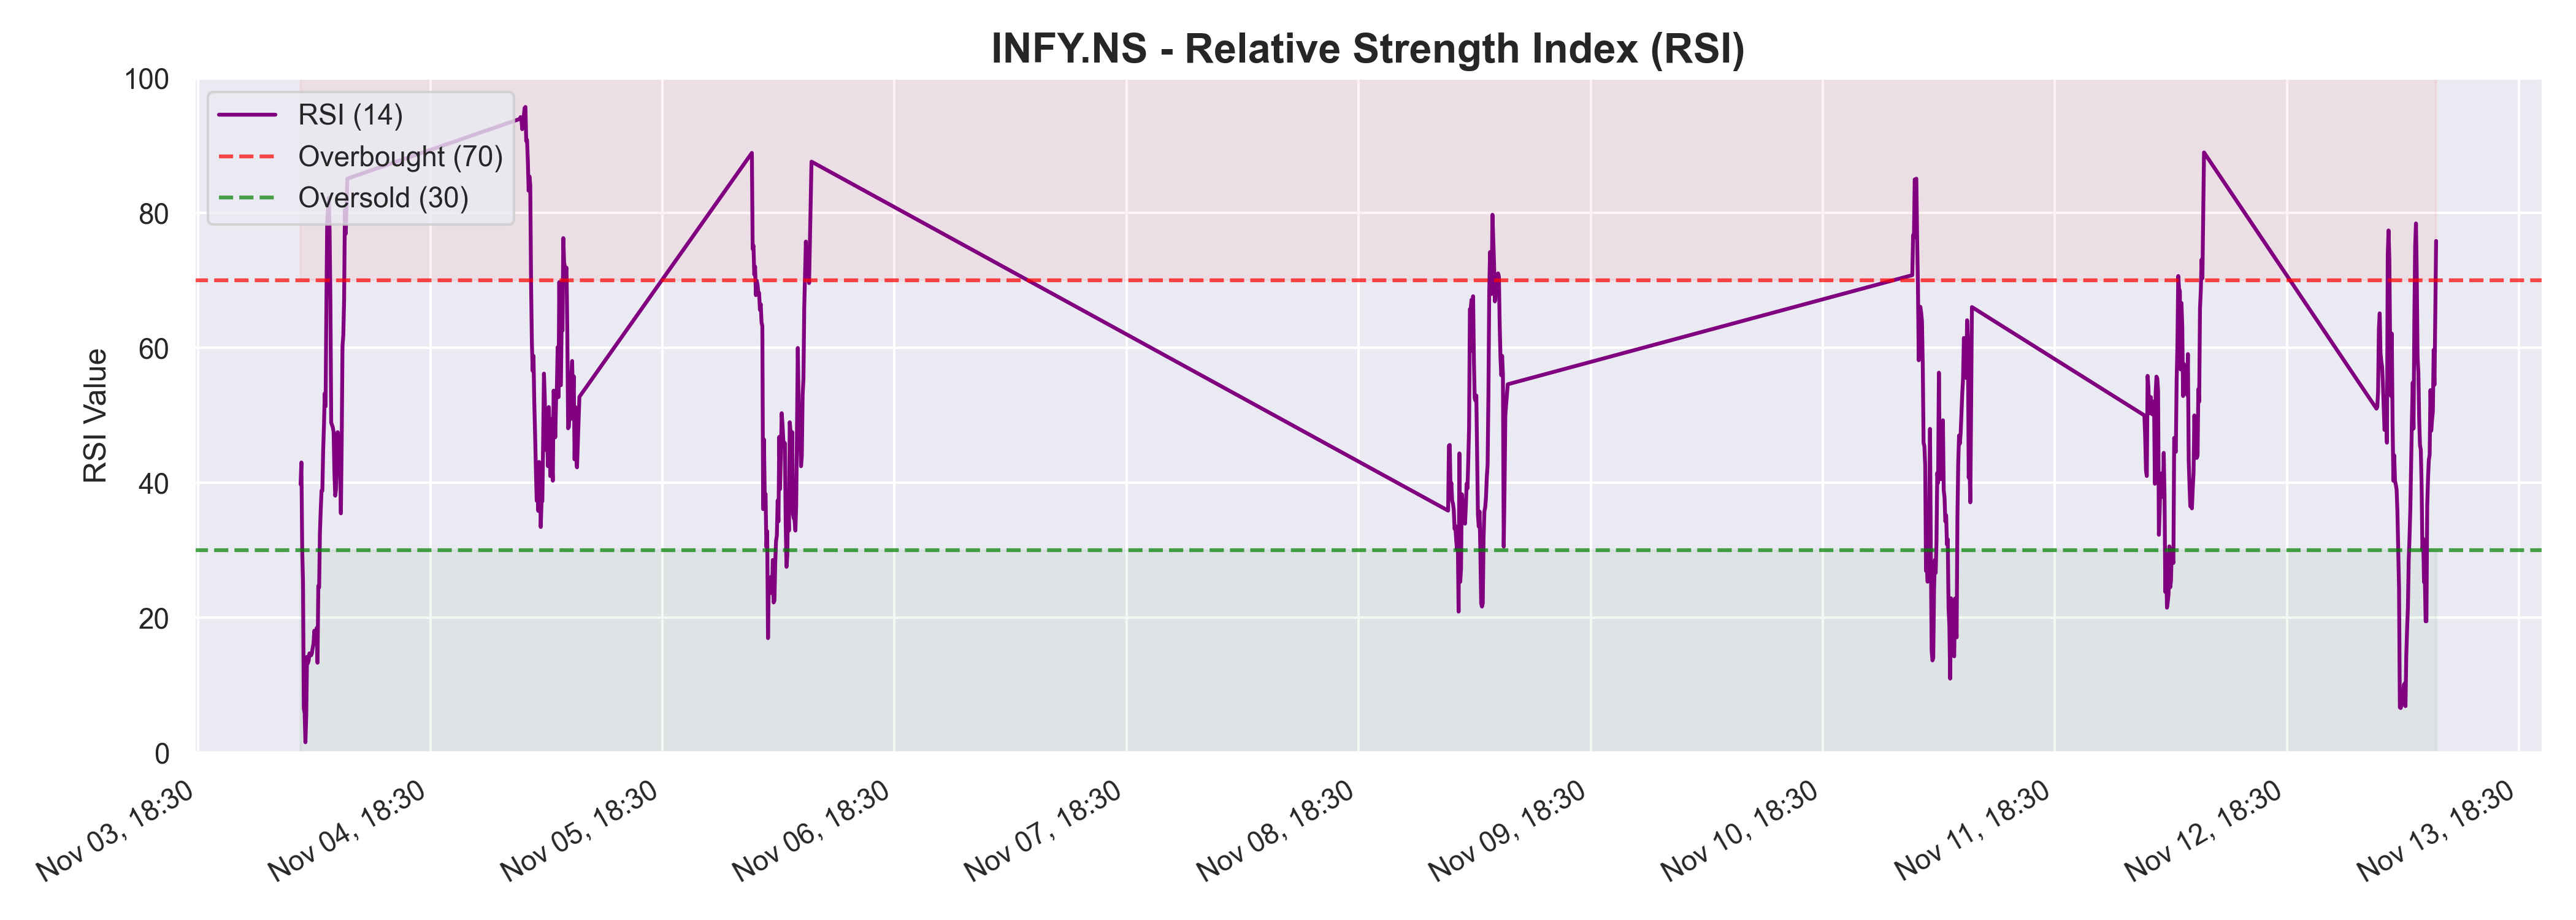


--- CORRELATION HEATMAP ---


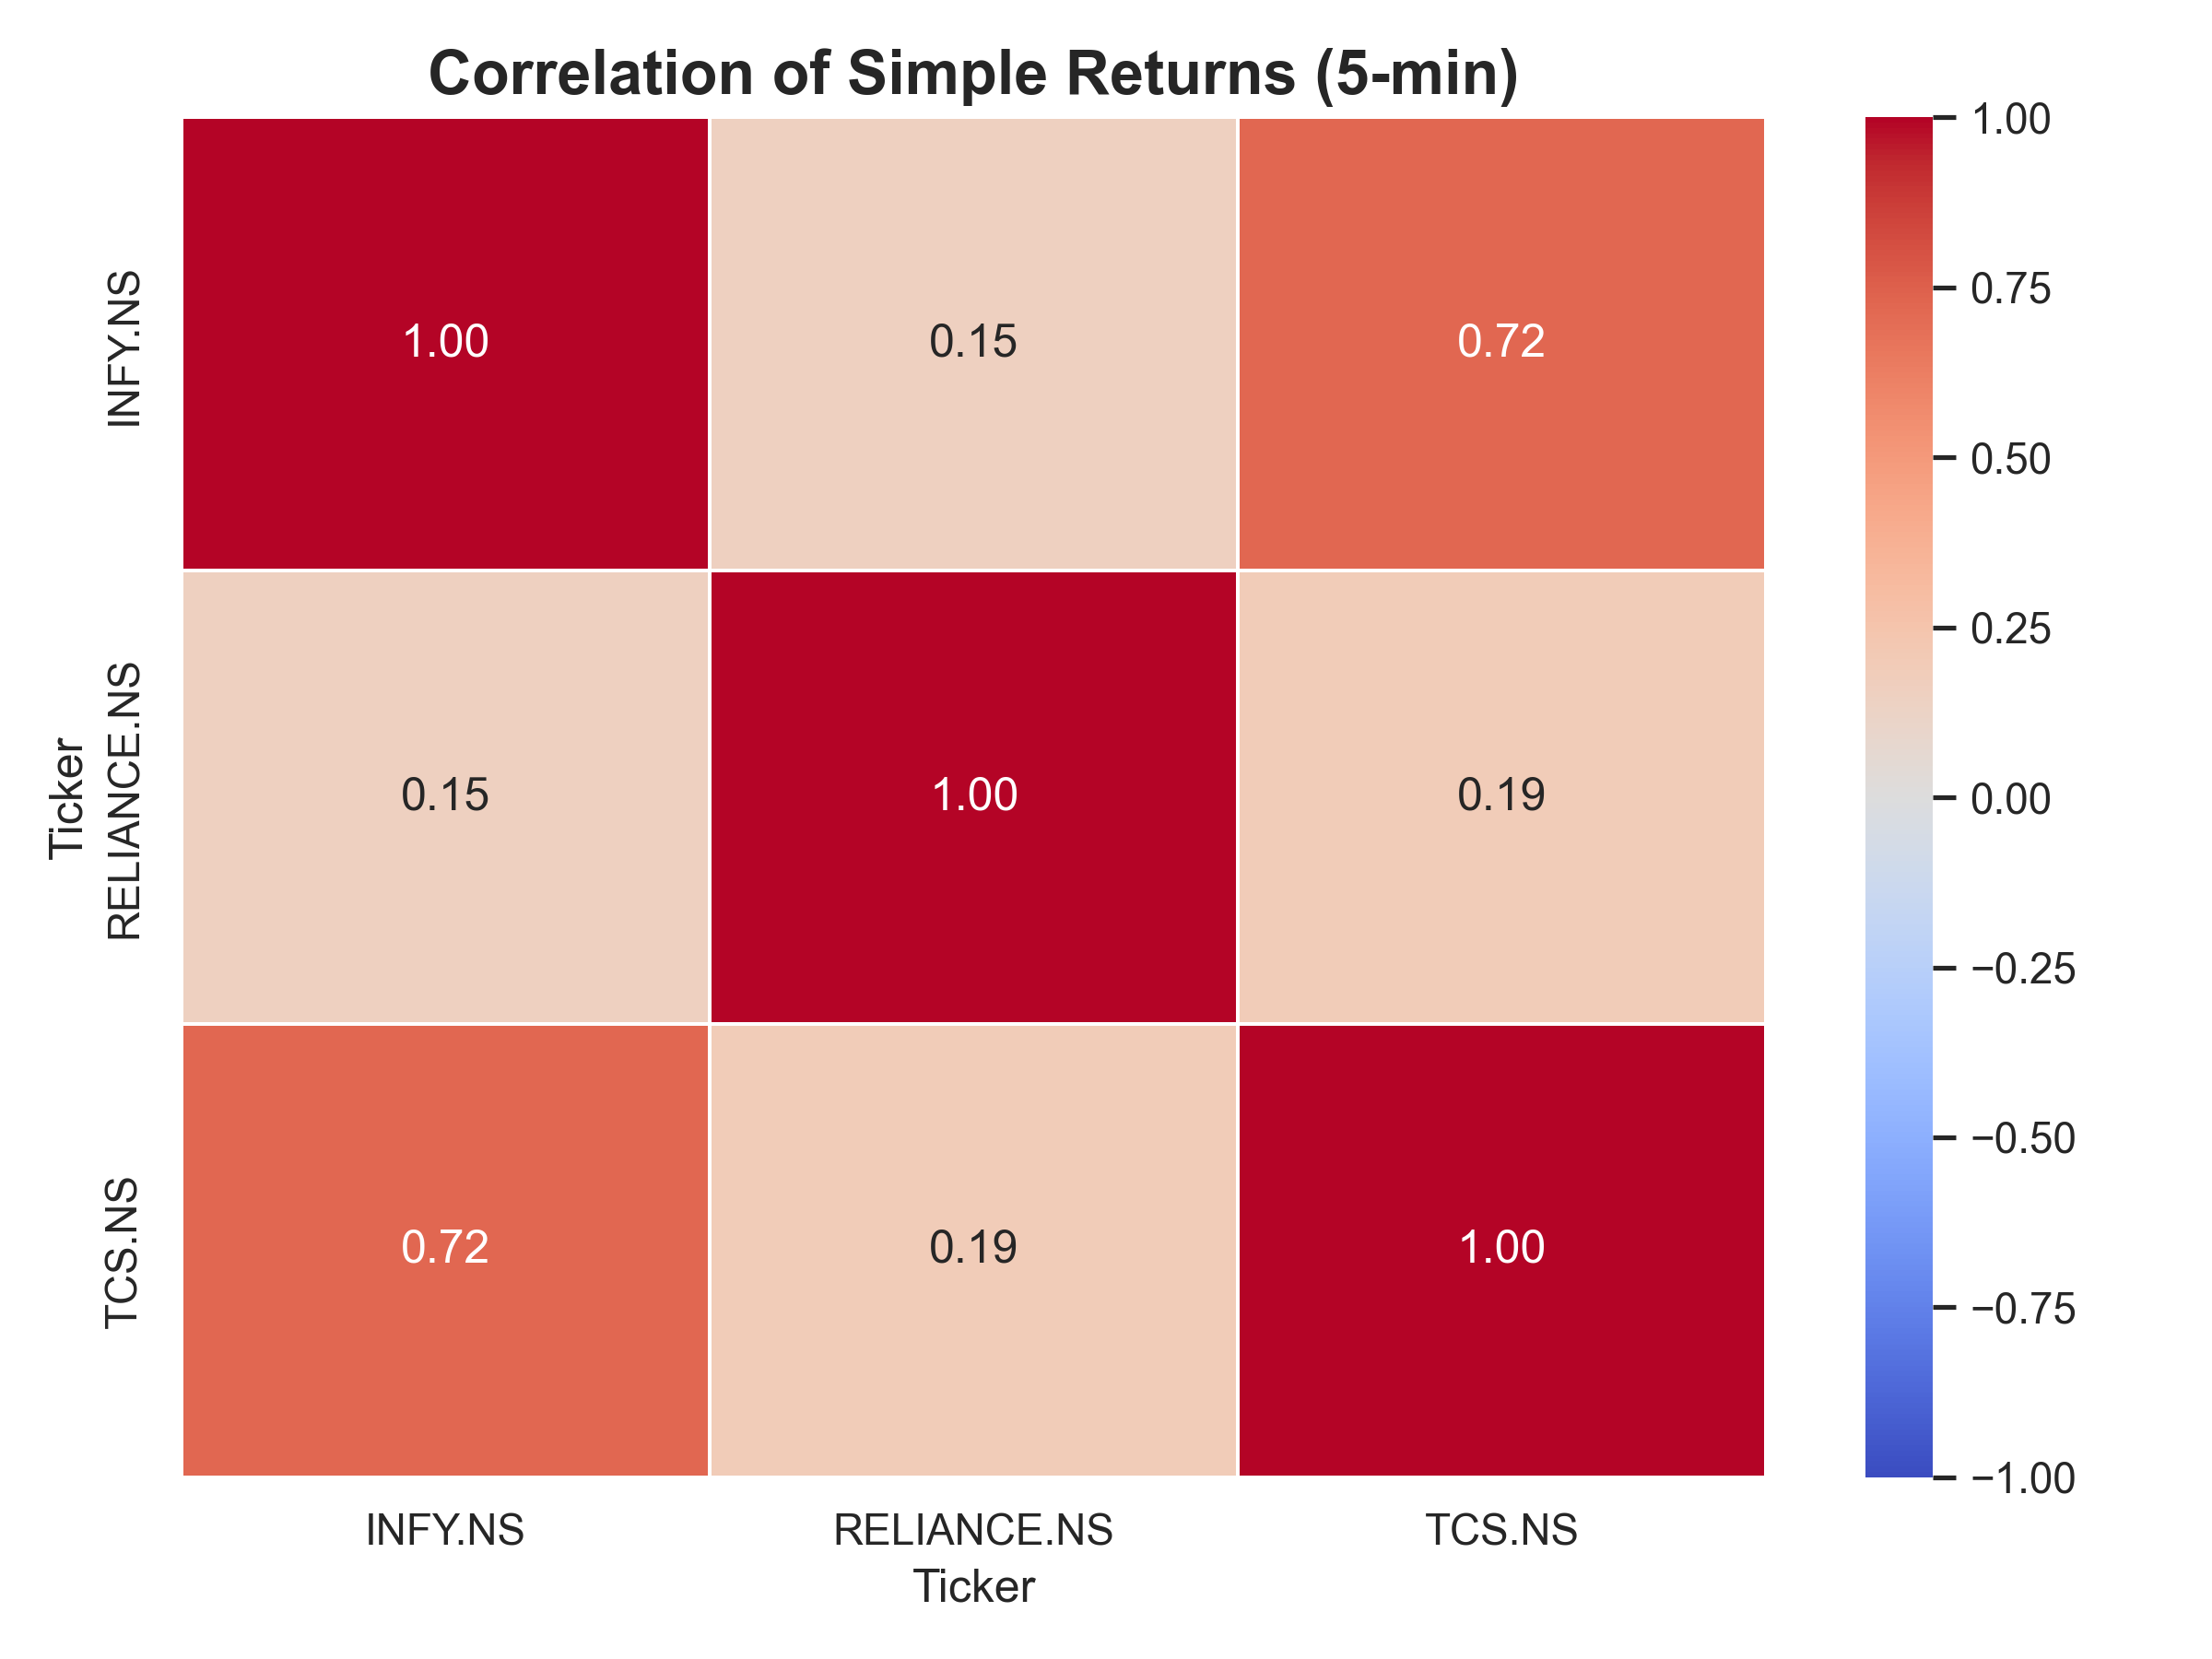


--- RETURN DISTRIBUTION (FAT TAILS) ---


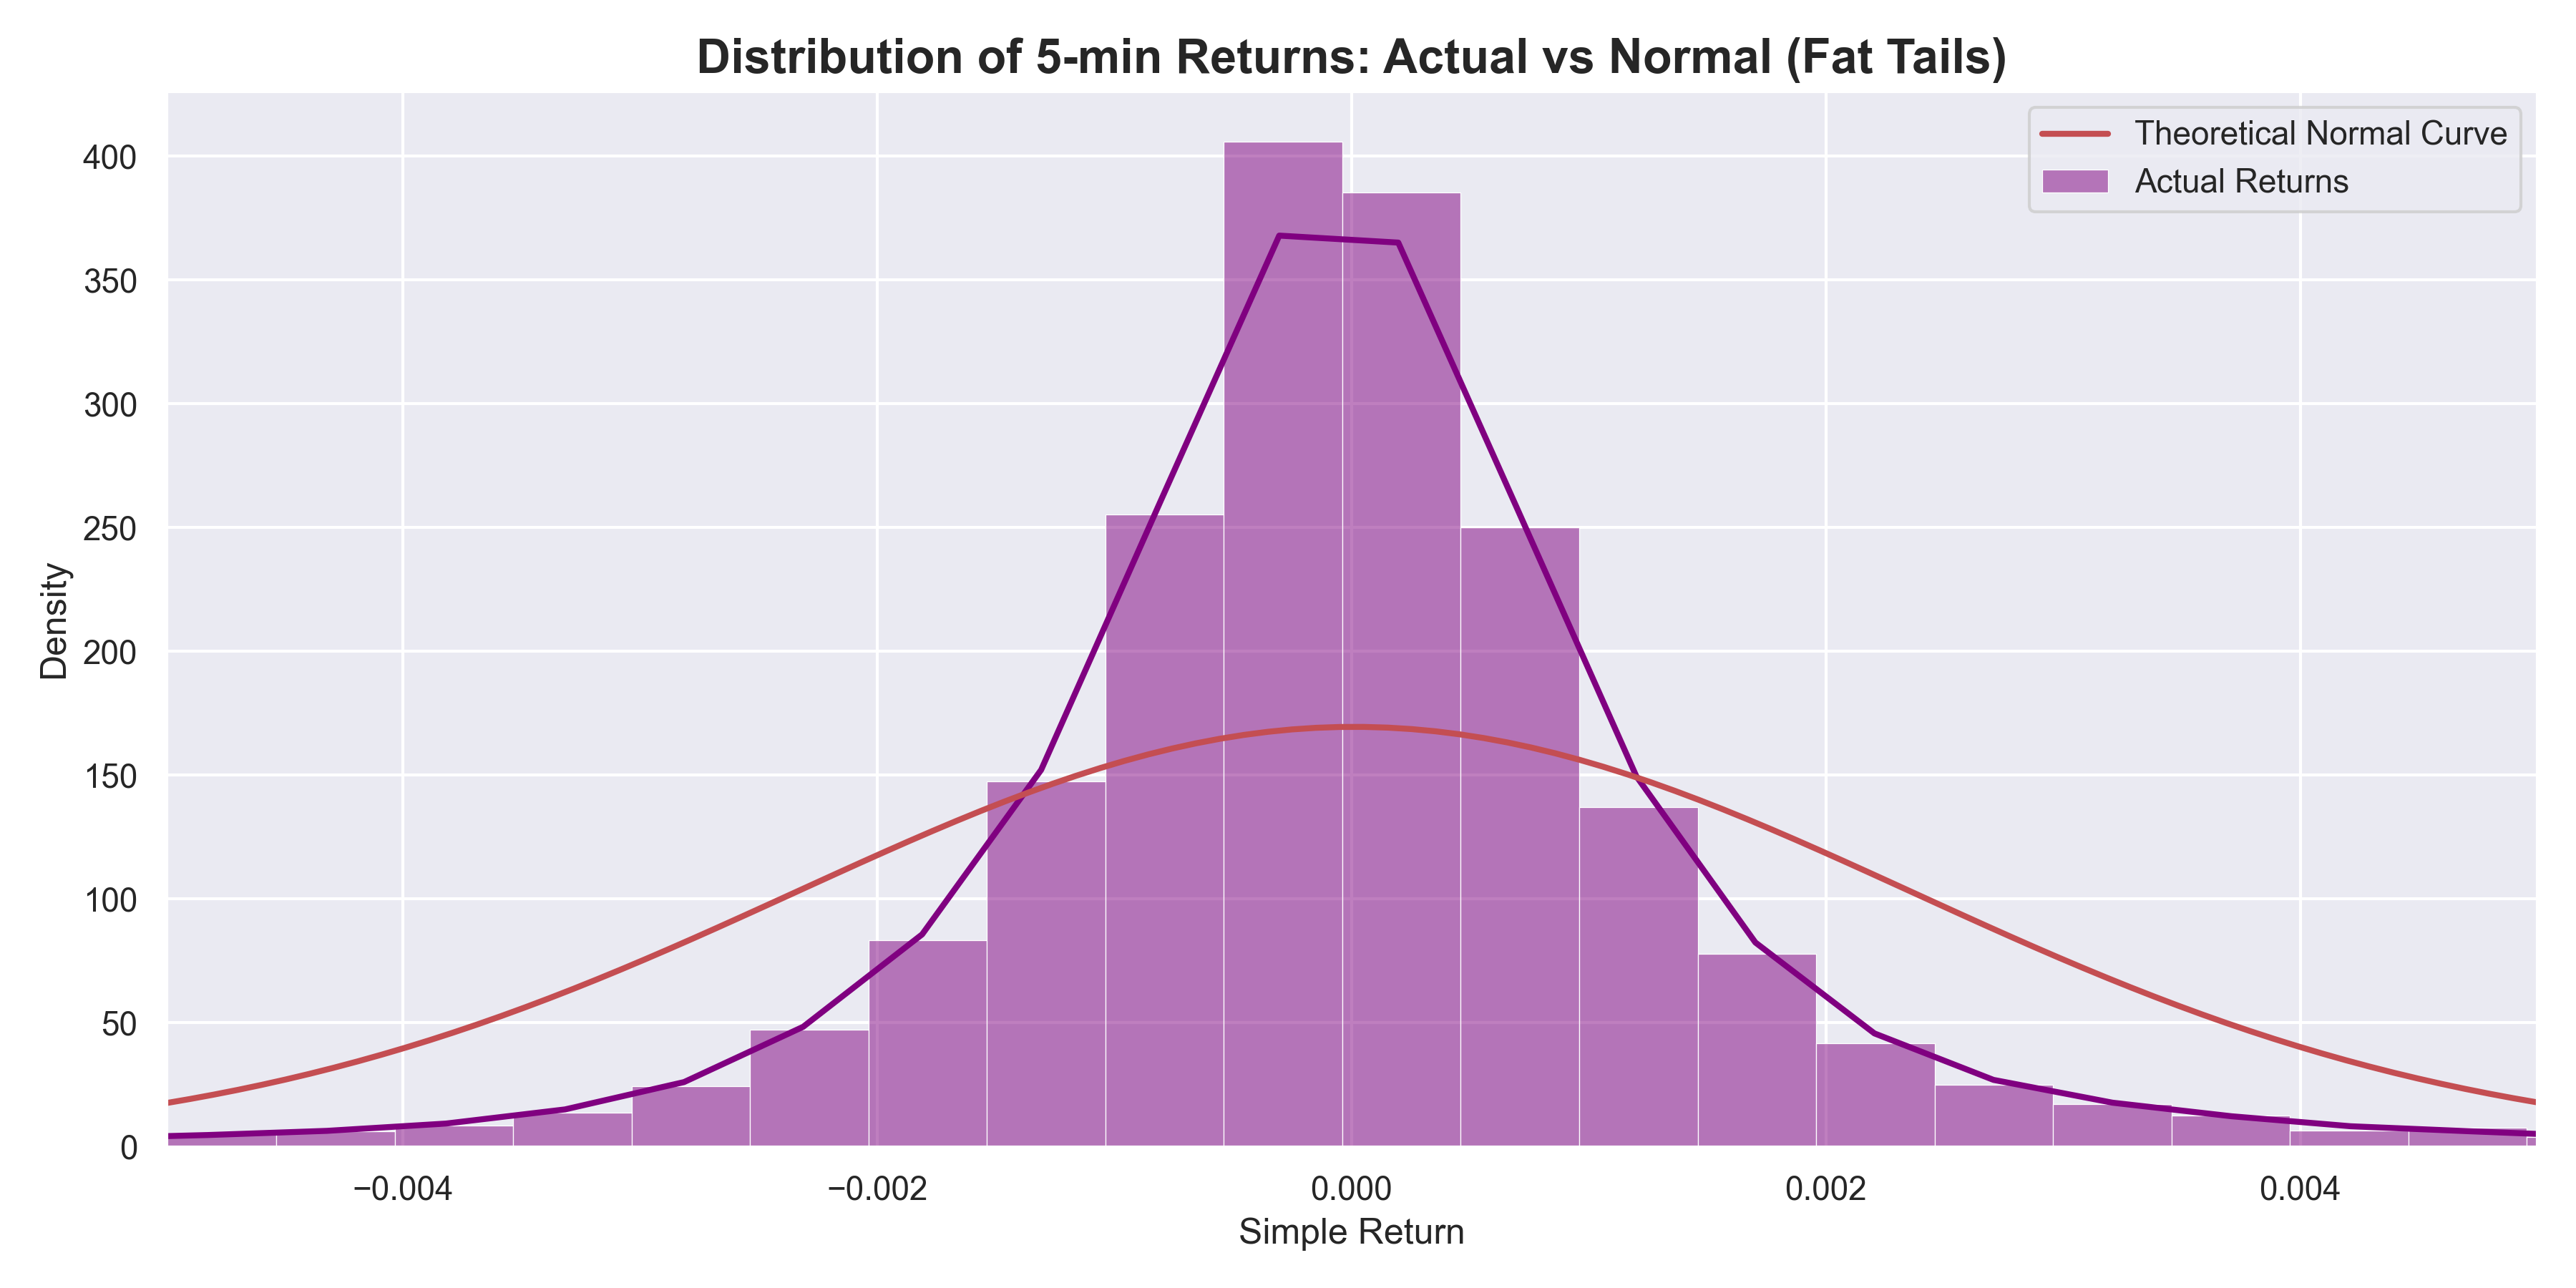

In [5]:
from IPython.display import Image, display

# Generate all charts
vis.plot_moving_averages(clean_df, 'RELIANCE.NS')
vis.plot_bollinger_bands(clean_df, 'TCS.NS')
vis.plot_rsi(clean_df, 'INFY.NS')
vis.plot_correlation_heatmap(clean_df)
vis.plot_return_distribution(clean_df)

# Display them inline
print("\n--- RELIANCE.NS: MOVING AVERAGES ---")
display(Image(filename='../visualizations/RELIANCE_NS_moving_averages.png'))

print("\n--- TCS.NS: BOLLINGER BANDS ---")
display(Image(filename='../visualizations/TCS_NS_bollinger_bands.png'))

print("\n--- INFY.NS: RSI ---")
display(Image(filename='../visualizations/INFY_NS_rsi.png'))

print("\n--- CORRELATION HEATMAP ---")
display(Image(filename='../visualizations/correlation_heatmap.png'))

print("\n--- RETURN DISTRIBUTION (FAT TAILS) ---")
display(Image(filename='../visualizations/return_distribution.png'))

## 5. Predictive Modeling
We will build three models, progressing from the simplest possible approach to more complex machine learning algorithms, to see how well we can predict the immediate next 5-minute Close price.

### Model 1: Simple Linear Regression
First, we attempt to predict the next price using **only one feature**: the current Close price. This serves as our baseline.

In [9]:
# --- Simple Linear Regression (Using only ONE feature) ---
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# 1. Define X with ONLY one feature (Current Close)
X_simple = ml_df[['Close']] 
y_simple = ml_df['Next_Close']

# 2. Split (Chronological)
split_idx = int(len(ml_df) * 0.8)
X_train_s, X_test_s = X_simple.iloc[:split_idx], X_simple.iloc[split_idx:]
y_train_s, y_test_s = y_simple.iloc[:split_idx], y_simple.iloc[split_idx:]

# 3. Train
simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)

# 4. Predict & Score
simple_predictions = simple_model.predict(X_test_s)
simple_r2 = r2_score(y_test_s, simple_predictions)

print(f"Simple Linear Regression R-squared: {simple_r2:.4f}")
print(f"Equation: Next_Close = {simple_model.coef_[0]:.4f} * Close + {simple_model.intercept_:.4f}")

Simple Linear Regression R-squared: 1.0000
Equation: Next_Close = 1.0000 * Close + -0.0371


### Model 2: Multiple Linear Regression
Next, we introduce multiple features (Open, High, Low, Volume, SMA, RSI) to see if adding more context improves our model's ability to predict the next price.

In [10]:
# --- Model 2: Multiple Linear Regression ---
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Prepare the target: The NEXT 5-minute Close price for each stock
clean_df['Next_Close'] = clean_df.groupby('Ticker')['Close'].shift(-1)

# 2. Drop ALL rows with NaN values (This is the fix we discussed!)
ml_df = clean_df.dropna().copy() 

# 3. Define features (X) and target (y)
features = ['Open', 'High', 'Low', 'Close', 'Volume', 'SMA_20', 'RSI_14']
X = ml_df[features]
y = ml_df['Next_Close']

# 4. Chronological Train/Test Split (80% train, 20% test)
split_index = int(len(ml_df) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# 5. Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# 6. Make predictions
predictions = model.predict(X_test)

# 7. Evaluate the model
r2 = r2_score(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print(f"Multiple Linear Regression R-squared: {r2:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} INR")

Multiple Linear Regression R-squared: 1.0000
Root Mean Squared Error (RMSE): 3.79 INR


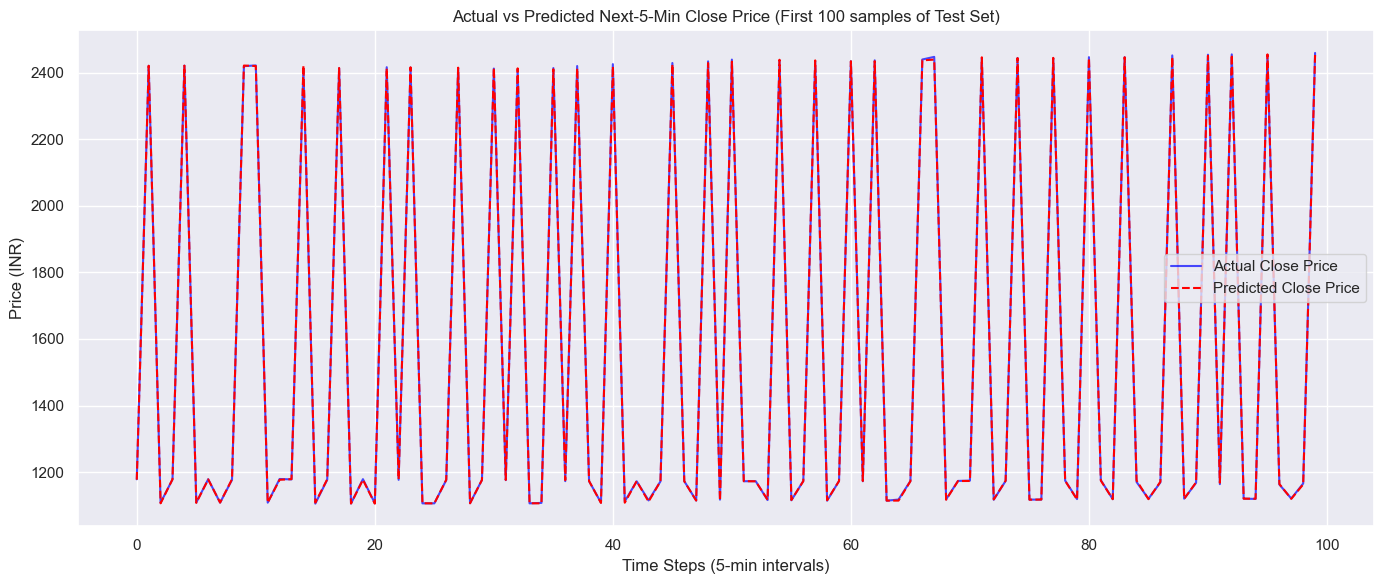

In [7]:
# Visualizing Actual vs Predicted for the Test Set
plt.figure(figsize=(14, 6))
plt.plot(y_test.values[:100], label='Actual Close Price', color='blue', alpha=0.7)
plt.plot(predictions[:100], label='Predicted Close Price', color='red', linestyle='--')
plt.title('Actual vs Predicted Next-5-Min Close Price (First 100 samples of Test Set)')
plt.xlabel('Time Steps (5-min intervals)')
plt.ylabel('Price (INR)')
plt.legend()
plt.tight_layout()
plt.show()

### Model 3: Random Forest Classifier (Direction Prediction)
Predicting the exact price (Regression) resulted in near-perfect R² scores due to autocorrelation (the next price is always very close to the current price). However, traders don't care about a 3-paise difference; they care about **direction**. 

In this model, we change the problem to a **Classification** task: Will the next 5-minute price go **UP (1)** or **DOWN (0)**? We use a Random Forest Classifier, which is capable of finding complex, non-linear patterns in the market.

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# 1. Create the Direction Target (1 if next price > current price, 0 if lower)
ml_df['Direction'] = (ml_df['Next_Close'] > ml_df['Close']).astype(int)

# 2. Define Features and Target
X_dir = ml_df[features]
y_dir = ml_df['Direction']

# 3. Chronological Train/Test Split (80% train, 20% test)
split_idx = int(len(ml_df) * 0.8)
X_train_d, X_test_d = X_dir.iloc[:split_idx], X_dir.iloc[split_idx:]
y_train_d, y_test_d = y_dir.iloc[:split_idx], y_dir.iloc[split_idx:]

# 4. Train the Random Forest Classifier
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train_d, y_train_d)

# 5. Predict Direction
dir_predictions = clf.predict(X_test_d)

# 6. Evaluate
acc = accuracy_score(y_test_d, dir_predictions)
print(f"Direction Prediction Accuracy: {acc:.4f} (or {acc*100:.2f}%)")
print("\n--- Classification Report ---")
print(classification_report(y_test_d, dir_predictions, target_names=['DOWN (0)', 'UP (1)']))

Direction Prediction Accuracy: 0.5200 (or 52.00%)

--- Classification Report ---
              precision    recall  f1-score   support

    DOWN (0)       0.54      0.63      0.58      1385
      UP (1)       0.48      0.39      0.43      1219

    accuracy                           0.52      2604
   macro avg       0.51      0.51      0.51      2604
weighted avg       0.51      0.52      0.51      2604



## 6. Conclusion & Findings

This project successfully demonstrated the end-to-end process of building a quantitative financial analysis pipeline, from data acquisition to machine learning. By analyzing 60 days of 5-minute intraday data for RELIANCE, TCS, and INFY, we uncovered several critical market dynamics:

* **Risk-Adjusted Performance (Sharpe Ratio):** Analyzing raw returns is insufficient in financial markets. By calculating the Sharpe Ratio, we identified that **TCS** offered the most efficient risk-adjusted returns (0.77) over this period, outperforming both RELIANCE and INFY. This highlights the importance of measuring return per unit of volatility.

* **Sector Correlation & Portfolio Diversification:** The correlation matrix revealed a strong positive correlation (~0.72) between the two IT stocks (TCS & Infosys), indicating that they are subject to the same macroeconomic and sector-specific forces. Conversely, Reliance exhibited a very low correlation (~0.15) with the IT sector. For a portfolio manager, this proves that adding Reliance to a portfolio of IT stocks provides excellent diversification benefits, significantly reducing systemic risk.

* **Non-Normality & Fat Tails (Kurtosis):** High-frequency returns are rarely normally distributed. Our visualizations and statistical metrics (Kurtosis > 90) proved the existence of "fat tails"—extreme price swings occur far more frequently than a standard bell curve predicts. This is a crucial insight for risk management and option pricing, where standard Gaussian models underestimate the probability of market crashes.

* **Predictive Modeling: The Autocorrelation Trap:** 
    * *Regression Models:* Our initial models (Simple and Multiple Linear Regression) achieved near-perfect R-squared scores. However, we identified that this was a statistical artifact known as **autocorrelation**—the model was simply predicting that the next 5-minute price would mirror the current price. This provides no real trading edge.
    * *Classification Model:* To address this, we built a **Random Forest Classifier** to predict the *direction* of price movement (Up or Down) rather than the exact price. The model achieved an overall accuracy of **52%**, successfully finding a weak but exploitable signal in what is largely a noisy market. Notably, it achieved a **63% recall on downward movements**, successfully capturing the rapid, fear-driven sell-offs that characterize intraday trading. 

**Final Word:** This project proves that while high-frequency data is heavily influenced by short-term price continuity, modern machine learning (when applied to direction classification rather than price regression) can extract actionable insights from complex market noise.